## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [1]:
import requests

URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates?limit=1200'

# данные из апи (файл качать не надо)
laureates_response = requests.get(URL_LAUREATES)
laureates = laureates_response.json()

Тип лауреата определяю по ключу в исходном словаре: у человека есть `knownName`, у организации `orgName`. Дальше каждый словарь прогоняется через свой процессор и складывается в общий список.

In [2]:
from laureates_configs import process_orgs, process_persons


def get_laureate_data(laureate: dict) -> dict:
    """Определяет тип лауреата (человек или организация) и обрабатывает его."""
    if 'knownName' in laureate:
        data = process_persons(laureate)
        data['type_'] = 'person'
    else:
        data = process_orgs(laureate)
        data['type_'] = 'org'

    return data


laureates_data = []

for laureate in laureates['laureates']:
    laureates_data.append(get_laureate_data(laureate))

laureates_data[:2]



### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

In [3]:
# проверка, что процессоры собрали нужные поля
assert len(laureates_data) == len(laureates['laureates'])
assert laureates_data[0]['type_'] in ('person', 'org')
assert isinstance(laureates_data[0]['id'], int)

persons = [row for row in laureates_data if row['type_'] == 'person']
orgs = [row for row in laureates_data if row['type_'] == 'org']

print('всего записей:', len(laureates_data))
print('людей:', len(persons))
print('организаций:', len(orgs))

всего записей: 1028
людей: 1000
организаций: 28


Дальше по ноутбуку понадобятся мои модули (`aggregations`, `dataset_helpers`, `atribute_manager`, `stopwords`) и matplotlib для графиков.

In [4]:
# все импорты в одном месте, дальше по ноутбуку их не будет
import matplotlib.pyplot as plt

from aggregations import count_rows, mean_value, median_value, top_n
from atribute_manager import add_attribute, count_missing
from dataset_helpers import apply_aggregation, filter_rows, group_by_attributes
from stopwords import STOPWORDS

Считаю пропуски по каждому полю и смотрю их долю. Поля у людей и организаций разные, поэтому две таблички.

In [5]:
# у людей и организаций поля разные (поэтому отдельно)
missing_persons = count_missing(persons)
missing_orgs = count_missing(orgs)

print('пропуски у людей:', missing_persons)
print('пропуски у организаций:', missing_orgs)

share_persons = {field: round(count / len(persons), 3)
                 for field, count in missing_persons.items()}

print('доля пропусков у людей:', share_persons)

пропуски у людей: {'id': 0, 'name': 0, 'gender': 0, 'birth_year': 0, 'country_birth': 3, 'country_now': 3, 'prizes_relevant': 0, 'type_': 0}
пропуски у организаций: {'id': 0, 'name': 0, 'founded_year': 1, 'country_founded': 4, 'country_now': 4, 'prizes_relevant': 0, 'type_': 0}
доля пропусков у людей: {'id': 0.0, 'name': 0.0, 'gender': 0.0, 'birth_year': 0.0, 'country_birth': 0.003, 'country_now': 0.003, 'prizes_relevant': 0.0, 'type_': 0.0}


Пропусков почти нет: у людей пустые только `country_birth` и `country_now`, и всего у трех записей (это лауреаты, у которых в исходном json нет места рождения), то есть 0.3%. У организаций не заполнена страна основания у четырех из 28 и год основания у одной. Ключевые для анализа поля (`id`, `name`, `prizes_relevant`) заполнены всегда, так что чистить данные дополнительно не нужно.

In [6]:
ids = sorted(row['id'] for row in laureates_data)

by_id = {row['id']: row for row in laureates_data}

print('минимальный id:', ids[0], '->', by_id[ids[0]]['name'],
      [prize['award_year'] for prize in by_id[ids[0]]['prizes_relevant']])
print('максимальный id:', ids[-1], '->', by_id[ids[-1]]['name'],
      [prize['award_year'] for prize in by_id[ids[-1]]['prizes_relevant']])
print('повторяющиеся id:', len(ids) - len(set(ids)))

gaps = [(ids[i], ids[i + 1]) for i in range(len(ids) - 1)
        if ids[i + 1] - ids[i] > 1]

print('пар с разрывом больше 1:', len(gaps))
print('первые пять разрывов:', gaps[:5])

минимальный id: 1 -> Wilhelm Conrad Röntgen [1901]
максимальный id: 1070 -> Michael Woodford [2026]
повторяющиеся id: 0
пар с разрывом больше 1: 24
первые пять разрывов: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470)]


Id выдаются по порядку вручения: id = 1 у Рентгена с премией 1901 года, максимальный id - у лауреата 2026 года. Дублей нет совсем, а разрывов 24 - то есть несколько номеров в базе Нобелевского комитета пропущено (скорее всего они заняты записями, которые в публичный список не попали).

Дальше беру три темы: страны, возраст на момент первой премии и женщины-лауреатки. Плюс отдельно смотрю миграции, повторные премии и отказы.

## Тема 1. Страны

Считаю лауреата по стране рождения (`country_birth`). Сначала тотал, потом разрез по категориям.

In [7]:
def get_prize_rows(rows: list) -> list:
    """Раскладывает лауреатов в список призов (строка - один приз)."""
    prize_rows = []

    for row in rows:
        for prize in row['prizes_relevant']:
            prize_row = dict(prize)
            prize_row['name'] = row['name']
            prize_row['id'] = row['id']
            prize_row['type_'] = row['type_']
            prize_row['gender'] = row.get('gender')
            prize_row['birth_year'] = row.get('birth_year')
            prize_row['country_birth'] = row.get('country_birth')
            prize_row['country_now'] = row.get('country_now')
            prize_row['decade'] = prize['award_year'] // 10 * 10
            prize_rows.append(prize_row)

    return prize_rows


prize_rows = get_prize_rows(laureates_data)
received = filter_rows(prize_rows, {'prize_status': 'received'})

print('всего призов:', len(prize_rows))
print('из них полученных:', len(received))

всего призов: 1036
из них полученных: 1033


Для топов нужны две вспомогательные функции: одна группирует и считает, вторая печатает результат по строчкам.

In [8]:
def count_by(rows: list, attribute: str, n: int = 5) -> list:
    """Какие значения атрибута встречаются чаще всего."""
    groups = group_by_attributes(rows, [attribute])
    counts = apply_aggregation(groups, count_rows)
    counts.pop((None,), None)

    return top_n(counts, n)


def show_top(pairs: list, title: str) -> None:
    """Печатает топ по строчкам (так понятнее, чем кортежами)."""
    print(title)

    for key, value in pairs:
        print('   ', key[0], '-', value)

    print()


top_countries = count_by(received, 'country_birth', 5)

show_top(top_countries, 'Топ-5 стран по числу лауреатов:')

for category in sorted({row['category_en'] for row in received}):
    in_category = filter_rows(received, {'category_en': category})
    show_top(count_by(in_category, 'country_birth', 3),
             'Топ-3 страны, ' + category + ':')

Топ-5 стран по числу лауреатов:
    USA - 302
    United Kingdom - 95
    Germany - 82
    France - 60
    Japan - 31

Топ-3 страны, Chemistry:
    USA - 60
    United Kingdom - 27
    Germany - 24

Топ-3 страны, Economic Sciences:
    USA - 56
    United Kingdom - 7
    Canada - 5

Топ-3 страны, Literature:
    France - 11
    USA - 10
    Sweden - 7

Топ-3 страны, Peace:
    USA - 19
    France - 9
    Germany - 6

Топ-3 страны, Physics:
    USA - 72
    United Kingdom - 25
    Germany - 24

Топ-3 страны, Physiology or Medicine:
    USA - 85
    United Kingdom - 25
    Germany - 22



Топ-5 стран нагляднее на столбиках.

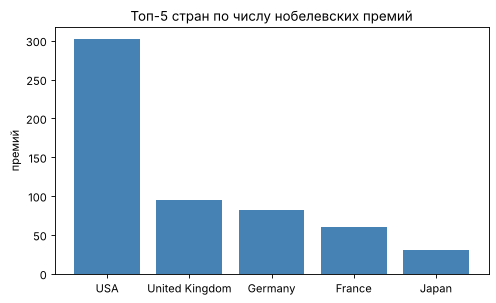

In [9]:
names = [key[0] for key, value in top_countries]
values = [value for key, value in top_countries]

plt.figure(figsize=(7, 4))
plt.bar(names, values, color='steelblue')
plt.title('Топ-5 стран по числу нобелевских премий')
plt.ylabel('премий')
plt.show()

США впереди с огромным отрывом (302 премии против 95 у Великобритании), дальше Германия, Франция и Япония. Но разрез по категориям показывает, что лидерство неодинаковое: в литературе первая Франция, в премии мира отрыв небольшой, а вот в экономике разрыв гигантский - 56 премий против 7 у Великобритании. Логично: премия по экономике появилась только в 1969 году, то есть уже в период американского доминирования в науке.

## Тема 2. Возраст на момент первой премии

Беру только лауреатов-людей, у которых известен год рождения. Для каждого нахожу самый ранний полученный приз и считаю разницу в годах.

In [10]:
def get_first_prizes(rows: list) -> list:
    """Самый ранний полученный приз каждого человека."""
    first_prizes = []

    for row in rows:
        received_prizes = [prize for prize in row['prizes_relevant']
                           if prize['prize_status'] == 'received']

        if row['type_'] != 'person' or not received_prizes:
            continue

        if not row['birth_year']:
            continue

        first = min(received_prizes, key=lambda prize: prize['award_year'])
        first_prizes.append({
            'name': row['name'],
            'gender': row['gender'],
            'category_en': first['category_en'],
            'award_year': first['award_year'],
            'decade': first['award_year'] // 10 * 10,
            'age': first['award_year'] - row['birth_year'],
        })

    return first_prizes


first_prizes = get_first_prizes(laureates_data)

print('лауреатов с известным возрастом:', len(first_prizes))
print('средний возраст:', mean_value(first_prizes, 'age'))
print('медианный возраст:', median_value(first_prizes, 'age'))

лауреатов с известным возрастом: 997
средний возраст: 60.6
медианный возраст: 61


Теперь тот же возраст, но в разрезе категорий - и среднее, и медиана, чтобы увидеть перекос.

In [11]:
def output_metric_by_category(rows: list, attribute: str, metric,
                              field: str) -> dict:
    """Считает метрику по группам и печатает по порядку."""
    groups = group_by_attributes(rows, [attribute])
    values = apply_aggregation(groups, metric, field)
    values = {key[0]: value for key, value in values.items()}

    for key in sorted(values):
        print('   ', key, '-', values[key])

    return values


print('Средний возраст первой премии по категориям:')
output_metric_by_category(first_prizes, 'category_en', mean_value, 'age')

print()
print('Медианный возраст по категориям:')
output_metric_by_category(first_prizes, 'category_en', median_value, 'age')

Средний возраст первой премии по категориям:
    Chemistry - 59.43
    Economic Sciences - 67.21
    Literature - 65.07
    Peace - 60.96
    Physics - 57.79
    Physiology or Medicine - 59.02

Медианный возраст по категориям:
    Chemistry - 58
    Economic Sciences - 67
    Literature - 67
    Peace - 62
    Physics - 56.0
    Physiology or Medicine - 58


И динамика по десятилетиям.

    1900 - 57.84
    1910 - 53.08
    1920 - 54.98
    1930 - 51.62
    1940 - 58.02
    1950 - 54.13
    1960 - 56.41
    1970 - 59.32
    1980 - 60.54
    1990 - 62.14
    2000 - 65.87
    2010 - 66.85
    2020 - 69.38


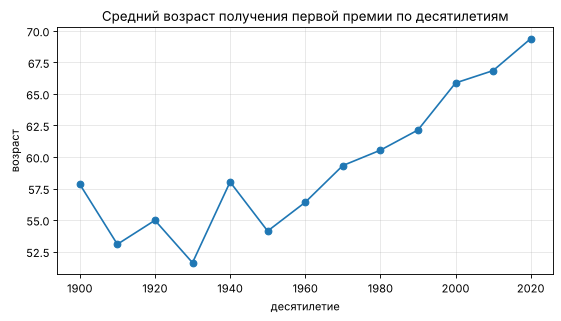

In [12]:
by_decade = output_metric_by_category(first_prizes, 'decade',
                                      mean_value, 'age')

decades = sorted(by_decade)

plt.figure(figsize=(8, 4))
plt.plot(decades, [by_decade[decade] for decade in decades], marker='o')
plt.title('Средний возраст получения первой премии по десятилетиям')
plt.xlabel('десятилетие')
plt.ylabel('возраст')
plt.grid(alpha=0.3)
plt.show()

Средний возраст 60.6, медиана 61 - они почти совпадают, значит выбросов, которые тянули бы среднее, тут нет. По категориям разброс заметный: младше всех физики (почти 58), старше всех экономисты (67). В динамике возраст сильно растет: в 1930-х премию получали в среднем в 52 года, в 2020-х - в 69. Похоже, премию все чаще дают за работы, сделанные десятилетия назад, и очередь на признание стала длиннее.

## Тема 3. Женщины-лауреатки

In [13]:
women = filter_rows(received, {'gender': 'female'})
men = filter_rows(received, {'gender': 'male'})

print('премий у женщин:', len(women))
print('премий у мужчин:', len(men))
share_women = len(women) / (len(women) + len(men)) * 100

print('доля женщин:', round(share_women, 1), '%')

print()
print('Женщины по десятилетиям:')
women_by_decade = apply_aggregation(group_by_attributes(women, ['decade']),
                                    count_rows)
women_by_decade = {key[0]: value for key, value in women_by_decade.items()}

for decade in sorted(women_by_decade):
    print('   ', decade, '-', women_by_decade[decade])

премий у женщин: 70
премий у мужчин: 932
доля женщин: 7.0 %

Женщины по десятилетиям:
    1900 - 3
    1910 - 1
    1920 - 2
    1930 - 3
    1940 - 3
    1960 - 3
    1970 - 4
    1980 - 4
    1990 - 7
    2000 - 11
    2010 - 13
    2020 - 16


То же самое на графике плюс разрез по категориям - за все годы и отдельно с 2000 года.

Женщины по категориям за все годы:

    Peace - 21
    Literature - 19
    Physiology or Medicine - 14
    Chemistry - 8
    Physics - 5
    Economic Sciences - 3

Женщины по категориям с 2000 года:
    Peace - 11
    Literature - 10
    Physiology or Medicine - 8
    Chemistry - 5
    Physics - 3
    Economic Sciences - 3



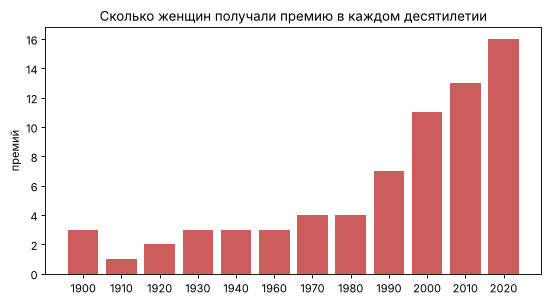

In [14]:
decades = sorted(women_by_decade)

plt.figure(figsize=(8, 4))
plt.bar([str(decade) for decade in decades],
        [women_by_decade[decade] for decade in decades], color='indianred')
plt.title('Сколько женщин получали премию в каждом десятилетии')
plt.ylabel('премий')
plt.show()

print('Женщины по категориям за все годы:')
show_top(count_by(women, 'category_en', 6), '')

last_years = filter_rows(women, {'award_year': lambda year: year >= 2000})

show_top(count_by(last_years, 'category_en', 6),
         'Женщины по категориям с 2000 года:')

Женщин среди лауреатов 7%, но по десятилетиям видно явное ускорение: до 1970-х это единичные премии, а за 2010-е и 2020-е их 29, то есть больше, чем за первые полвека вместе взятые. По категориям лидируют премия мира (21) и литература (19), и с 2000 года порядок тот же. Но интересно другое: больше половины всех женских премий по химии, физике и экономике приходится как раз на последние двадцать с небольшим лет, то есть естественные науки подтягиваются, просто с очень низкой базы.

## Миграции, повторные премии и отказы

In [15]:
# country_birth - название страны при рождении лауреата,
# country_now - та же точка на карте в сегодняшних границах.
# разница между ними получается из-за перекроенных границ
add_attribute(laureates_data,
              'country_of_origin_adjusted_for_migration',
              lambda row: row.get('country_now') or row.get('country_birth'))

changed = [row for row in laureates_data
           if row.get('country_birth') and row.get('country_now')
           and row['country_birth'] != row['country_now']]

print('записей, где страна рождения и современная страна различаются:',
      len(changed))

for row in changed[:5]:
    print('   ', row['name'], ':',
          row['country_birth'], '->', row['country_now'])

записей, где страна рождения и современная страна различаются: 113
    Aaron Ciechanover : British Protectorate of Palestine -> Israel
    Abdus Salam : India -> Pakistan
    Ada E. Yonath : British Mandate of Palestine -> Israel
    Adolf von Baeyer : Prussia -> Germany
    Albert A. Michelson : Prussia -> Poland


Считаю, какие страны чаще всего стоят в начале такой пары, а какие в конце.

In [16]:
outflow = {}
inflow = {}

for row in changed:
    outflow[row['country_birth']] = outflow.get(row['country_birth'], 0) + 1
    inflow[row['country_now']] = inflow.get(row['country_now'], 0) + 1

show_top(top_n({(key,): value for key, value in outflow.items()}, 5),
         'Страны, которые «потеряли» лауреатов:')
show_top(top_n({(key,): value for key, value in inflow.items()}, 5),
         'Страны, которые «приобрели» лауреатов:')

orgs_changed = [row for row in orgs
                if row.get('country_founded') != row.get('country_now')]

print('организаций со сменой страны:', len(orgs_changed))

Страны, которые «потеряли» лауреатов:
    Russian Empire - 16
    Prussia - 13
    Germany - 13
    Austria-Hungary - 13
    USSR - 7

Страны, которые «приобрели» лауреатов:
    Poland - 22
    Germany - 17
    Russia - 11
    Israel - 6
    Czech Republic - 6

организаций со сменой страны: 0


Расхождение есть у 113 записей, и больше всего «потеряли» Российская империя, Пруссия, Австро-Венгрия и СССР, а «приобрели» Польша, Германия, Россия и Израиль. Это ровно то, о чем я писала в комментарии: различие тут про распад империй и перекройку границ (переезды почти ни при чем). Поэтому в поле `country_of_origin_adjusted_for_migration` я кладу современную страну места рождения - тогда ее расхождение со страной на момент вручения уже будет означать именно миграцию. Чтобы посчитать саму миграцию, нужна страна университета на момент вручения, а ее в текущем конфиге нет. У организаций расхождений нет вообще.

In [17]:
def filter_by_num_prizes(rows: list, min_prizes: int = 2) -> list:
    """Лауреаты, у которых премий не меньше min_prizes."""
    chosen = []

    for row in rows:
        received_prizes = [prize for prize in row['prizes_relevant']
                           if prize['prize_status'] == 'received']

        if len(received_prizes) >= min_prizes:
            chosen.append(row)

    return chosen


multiple = filter_by_num_prizes(laureates_data, 2)
three_times = filter_by_num_prizes(laureates_data, 3)

print('лауреатов с двумя и более премиями:', len(multiple))
print('с тремя:', [row['name'] for row in three_times])

gaps_between = []

for row in multiple:
    years = sorted(prize['award_year'] for prize in row['prizes_relevant']
                   if prize['prize_status'] == 'received')
    categories = [prize['category_en'] for prize in row['prizes_relevant']
                  if prize['prize_status'] == 'received']
    gaps_between.append(years[1] - years[0])
    print('   ', row['name'], years, categories)

print()
print('средний перерыв между первой и второй премией:',
      round(sum(gaps_between) / len(gaps_between), 1), 'лет')

лауреатов с двумя и более премиями: 7
с тремя: ['International Committee of the Red Cross']
    Frederick Sanger [1958, 1980] ['Chemistry', 'Chemistry']
    International Committee of the Red Cross [1917, 1944, 1963] ['Peace', 'Peace', 'Peace']
    John Bardeen [1956, 1972] ['Physics', 'Physics']
    K. Barry Sharpless [2001, 2022] ['Chemistry', 'Chemistry']
    Linus Pauling [1954, 1962] ['Chemistry', 'Peace']
    Marie Curie [1903, 1911] ['Physics', 'Chemistry']
    Office of the United Nations High Commissioner for Refugees [1954, 1981] ['Peace', 'Peace']

средний перерыв между первой и второй премией: 18.4 лет


И отдельно отказы от премии.

In [18]:
declined = filter_rows(prize_rows, {'prize_status': 'declined'})

show_top(count_by(declined, 'category_en', 5), 'Отказы по категориям:')

for row in declined:
    print('   ', row['name'], row['award_year'],
          row['category_en'], row['type_'])

Отказы по категориям:
    Literature - 1
    Peace - 1

    Jean-Paul Sartre 1964 Literature person
    Le Duc Tho  1973 Peace person


Повторных лауреатов всего семь: пять людей и две организации, причем трижды премию получал только Красный Крест. Перерыв между первой и второй премией в среднем 18 лет. Категория почти всегда та же самая, исключений два - Мария Кюри (физика, потом химия) и Лайнус Полинг (химия, потом премия мира). Отказов тоже два, оба у людей: литература и премия мира, у организаций отказов нет.

## Бонус. Мотивации

Тексты мотиваций собираются сразу конфигом призов (поле `motivation_en`), так что отдельный парсинг тут уже лишний.

In [19]:
def get_words(text: str) -> list:
    """Режет текст на слова (без знаков препинания)."""
    cleaned = ''

    for symbol in text.lower():
        cleaned += symbol if symbol.isalpha() or symbol == ' ' else ' '

    return cleaned.split()


def count_words(rows: list, drop_stopwords: bool = False) -> dict:
    """Частоты слов в мотивациях."""
    counts = {}

    for row in rows:
        if not row['motivation_en']:
            continue

        for word in get_words(row['motivation_en']):
            if drop_stopwords and word in STOPWORDS:
                continue

            counts[word] = counts.get(word, 0) + 1

    return counts


raw_counts = count_words(received)

print('топ-50 слов без чистки:')
print([word for word, count in top_n(raw_counts, 50)])

топ-50 слов без чистки:
['of', 'the', 'for', 'and', 'in', 'their', 'his', 'to', 'discovery', 'discoveries', 'a', 'concerning', 'development', 'work', 'on', 'with', 'which', 'by', 'theory', 'contributions', 'has', 'structure', 'that', 'peace', 'recognition', 'economic', 'human', 'chemical', 'as', 'analysis', 'new', 'its', 'synthesis', 'pioneering', 'an', 'fundamental', 'efforts', 'between', 'chemistry', 'he', 'her', 'studies', 'through', 'international', 'method', 'especially', 'methods', 'role', 'having', 'research']


Теперь то же самое, но со стоп-словами из `stopwords.py`, и отдельно по каждой категории.

In [20]:
clean_counts = count_words(received, drop_stopwords=True)

print('топ-15 после чистки стоп-слов:')

for word, count in top_n(clean_counts, 15):
    print('   ', word, '-', count)

print()

for category in sorted({row['category_en'] for row in received}):
    in_category = filter_rows(received, {'category_en': category})
    words = count_words(in_category, drop_stopwords=True)
    print(category, ':', [word for word, count in top_n(words, 10)])

топ-15 после чистки стоп-слов:
    discovery - 211
    discoveries - 172
    concerning - 124
    development - 110
    work - 105
    theory - 74
    contributions - 61
    structure - 58
    peace - 53
    recognition - 48
    economic - 45
    human - 44
    chemical - 43
    analysis - 42
    new - 41

Chemistry : ['development', 'discovery', 'chemistry', 'chemical', 'synthesis', 'work', 'structure', 'organic', 'studies', 'contributions']
Economic Sciences : ['theory', 'economic', 'analysis', 'contributions', 'having', 'pioneering', 'research', 'markets', 'financial', 'empirical']
Literature : ['human', 'life', 'poetry', 'poetic', 'i', 'art', 's', 'great', 'power', 'narrative']
Peace : ['peace', 'efforts', 'work', 'international', 'rights', 'between', 'war', 'peaceful', 'struggle', 'human']
Physics : ['discovery', 'development', 'discoveries', 'theory', 'contributions', 'quantum', 'fundamental', 'structure', 'work', 'physics']
Physiology or Medicine : ['discoveries', 'concerning', 

В сыром топ-50 почти все места занимают служебные слова английского языка (the, for, of, and), их я вынесла в `stopwords.py`. После чистки остаются слова, которые реально описывают, за что дают премию: discovery, development, contributions, theory, work. По категориям множества почти не пересекаются - у физиков это частицы и структура, у химиков реакции и методы, у медиков клетки и терапия, а в премии мира и литературе слова совсем другие (peace, rights, efforts). То есть по одному топ-10 слов можно угадать категорию даже без ее названия.


Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты? 

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз? 
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)

## Выводы

Если коротко, то данные рассказывают вот что.

- **США доминируют**: 302 премии против 95 у Великобритании, причем в экономике разрыв восьмикратный, а в литературе первая вообще Франция.
- **Лауреаты стареют**: средний возраст первой премии вырос с 52 лет в 1930-х до **69 лет в 2020-х**, среднее и медиана при этом почти совпадают, то есть дело не в паре возрастных выбросов.
- **Женщин мало, но все больше**: 7% за всю историю, при этом за 2010-е и 2020-е - 29 премий, больше чем за первые полвека вместе взятые.
- **Разница стран рождения - это границы, а не переезды**: 113 расхождений почти целиком объясняются распадом империй, поэтому в поле `country_of_origin_adjusted_for_migration` лежит современная страна места рождения.
- **Повторные премии - редкость**: семь лауреатов, из них трижды только Красный Крест, средний перерыв 18 лет, категория обычно та же (исключения - Кюри и Полинг).
- **Отказов всего два**: Сартр (литература, 1964) и Ле Дык Тхо (премия мира, 1973), среди организаций отказов нет.
- **По мотивациям видно категорию**: после чистки стоп-слов топ-10 слов у физиков, химиков и медиков почти не пересекаются.

Технически данные оказались чистыми: пропусков меньше процента, дублей по `id` нет, так что отдельная чистка не понадобилась.